In [14]:
#import important functions
## Import libraries and basic setups
import glob
import os
import sys
import xml.etree.ElementTree as ET
import json
import time
import pytz
import datetime as dt

## util libs
import pandas as pd
import numpy as np
import copy
import matplotlib.pyplot as plt
from collections import defaultdict
import ast

#import pdf save
from matplotlib.backends.backend_pdf import PdfPages

#Import function to calculate time run
import time

#Import function to save and open RF model
from joblib import dump, load

def your_function():
    time.sleep(1)

#Import function to calculate Initial_EF and Pre_pulse_EF 
def Index_EF(x):
    # Ensure 'Time' is datetime
    x['Time'] = pd.to_datetime(x['Time']).dt.floor('D')

    # Group by the 'Time' column and calculate the mean for each day
    daily_mean = x.groupby('Time')['Daily_EF'].mean().reset_index()

    # Set 'Time' as the DataFrame index again for rolling calculation
    daily_mean.set_index('Time', inplace=True)

    # Calculate the rolling mean of the past 14 days, excluding the current day
    daily_mean['Pre_pulse_EF'] = daily_mean['Daily_EF'].rolling(window=15, min_periods=14).mean().shift(2)


    # Calculate the rolling mean of 2 on the shifted data, then shift upwards by 1 to align
    daily_mean['Before_EF'] = daily_mean['Daily_EF'].rolling(window=3, min_periods=2).mean().shift(1)
    daily_mean['After_EF'] = daily_mean['Daily_EF'].rolling(window=2, min_periods = 2).mean().shift(-1)
    daily_mean['Initial_EF'] = daily_mean['After_EF'] - daily_mean['Before_EF']

    #merge 2 df
    x_final = pd.merge(x, daily_mean[['Initial_EF', 'Pre_pulse_EF']], on='Time', how='outer')
    #drop na value again
    x_final = x_final.dropna()
    
    return (x_final)

def change_NEE(x):
    # Ensure 'Time' is datetime
    #x['Time'] = pd.to_datetime(x['Time']).dt.floor('D')

    # Group by the 'Time' column and calculate the mean for each day
    daily_mean = x.groupby('Time')['NEE_VUT_REF'].mean().reset_index()

    # Set 'Time' as the DataFrame index again for rolling calculation
    daily_mean.set_index('Time', inplace=True)

    # Calculate the rolling mean of the past 14 days, excluding the current day
    daily_mean['Pre_pulse_NEE'] = daily_mean['NEE_VUT_REF'].rolling(window=3, min_periods=1).mean().shift(2)


    # Calculate the rolling mean of 2 on the shifted data, then shift upwards by 1 to align
    daily_mean['Before_NEE'] = daily_mean['NEE_VUT_REF'].rolling(window=2, min_periods=1).mean().shift(1)
    daily_mean['After_NEE'] = daily_mean['NEE_VUT_REF'].rolling(window=2, min_periods = 1).mean().shift(-1)
    daily_mean['Initial_NEE'] = daily_mean['After_NEE'] - daily_mean['Before_NEE']
    daily_mean['Mean_NEE'] = daily_mean['NEE_VUT_REF']


    #merge 2 df
    x_final = pd.merge(x, daily_mean[['Initial_NEE', 'Pre_pulse_NEE', 'Mean_NEE']], on='Time', how='outer')
    #drop na value again
    x_final = x_final.dropna()
    
    return (x_final)

#convert time column 
def convert_time_format(df, time_column):
    # Convert the time column to string to ensure proper formatting
    df[time_column] = df[time_column].astype(str)
    
    # Convert the time column to datetime format
    df['Time_full'] = pd.to_datetime(df[time_column], format='%Y%m%d%H%M')
    
    # Extract components from the datetime
    df['Time'] = df['Time_full'].dt.date
    df['Hour'] = df['Time_full'].dt.hour + df['Time_full'].dt.minute / 60
    df['Month'] = df['Time_full'].dt.month
    df['Year'] = df['Time_full'].dt.year
    df['DOY'] = df['Time_full'].dt.dayofyear

    return df


##change the start of the day
def time_adjust(df):
    # Convert the 'Time' column to datetime.date if not already
    df['Time'] = pd.to_datetime(df['Time'])
    
    # Make a copy of the 'Time' column for adjustments
    df['Time_adj'] = df['Time'].copy()

    # Get unique sorted dates for iteration
    unique_times = sorted(df['Time'].unique())

    # Loop through the unique times (except the last one to avoid index error)
    for i in range(len(unique_times) - 1):
        next_time = unique_times[i + 1]
        current_time = unique_times[i]
        
        # Check if consecutive dates
        if (next_time - current_time).days == 1:
            # Find indexes where conditions are met
            index_morning = df.index[(df['NIGHT'] == 1) & (df['Hour'] < 12) & (df['Time'] == next_time)]
            # Adjust the time for these indexes
            df.loc[index_morning, 'Time_adj'] = current_time

    # Handle the first unique time separately if it has morning entries with 'NIGHT' == 1
    first_time = unique_times[0]
    ini_index_morning = df.index[(df['Time'] == first_time) & (df['Hour'] < 12) & (df['NIGHT'] == 1)]
    df.loc[ini_index_morning, 'Time_adj'] = first_time - pd.DateOffset(days=1)

    # Assign adjusted time back to the 'Time' column
    df['Time'] = df['Time_adj']
    
    return df

#calculate EF
def daytimeEF_df(df):
    # Check if there are more than 100 points with good quality control for LE_F_MDS and H_F_MDS
    if (df[df['LE_F_MDS_QC'] == 0].shape[0] > 100 or df[df['H_F_MDS_QC'] == 0].shape[0] > 100):
        # Subset the data based on conditions
        df_sub = df[(df['LE_F_MDS_QC'] == 0) & (df['H_F_MDS_QC'] == 0) & (df['NIGHT'] != 1) & 
                    (df['H_F_MDS'] > 0) & (df['LE_F_MDS'] > 0)]
    else:
        # Use gap-filled data if fewer than 100 original H and LE data points meet QC criteria
        df_sub = df[(df['NIGHT'] != 1) & (df['H_F_MDS'] > 0) & (df['LE_F_MDS'] > 0)]

    # Calculate EF
    df_sub['EF'] = df_sub['LE_F_MDS'] / (df_sub['LE_F_MDS'] + df_sub['H_F_MDS'])
    
    # Aggregate to get daily mean EF
    df_EF = df_sub.groupby('Time')['EF'].mean().reset_index()
    df_EF.columns = ['Time', 'Daily_EF']
    
    # Convert Time to date if not already
    df_EF['Time'] = pd.to_datetime(df_EF['Time']).dt.floor('D')
    
    df_full = pd.merge(df, df_EF, on='Time', how='outer')
    return df_full

#pulse detection function 
def pulse_detection(df):
    
    #Filter for original data points
    df_sub = df[(df["NEE_VUT_REF_QC"] == 0)]

    # Ignore missing data
    features = ["Time_full", "Year", "Month", "Time", 'RECO_NT_VUT_REF', "GPP_NT_VUT_REF", "NEE_VUT_REF", "Daily_EF", "P_ERA"]
    feature_select = ["Month", "RECO_NT_VUT_REF", "NEE_VUT_REF", "Daily_EF", "P_ERA", "Initial_EF", "Pre_pulse_EF", "Initial_NEE", "Pre_pulse_NEE", 'Mean_NEE']
    df_sub_fil = df_sub[features].dropna()
    df_sub_fil = Index_EF(df_sub_fil)
    df_sub_fil = change_NEE(df_sub_fil)
    
    #pulse cluster identification
    y_pred = RF_classifier.predict(df_sub_fil[feature_select].to_numpy())

    df_sub_fil['pulse_pred'] = y_pred
    
    df_sub_short = df_sub_fil[["Time_full", 'pulse_pred']]
    df_sub_short.columns = ['Time_full', 'pulse_cluster']
    
    df_full = pd.merge(df, df_sub_short, on='Time_full', how='outer')
    return df_full

# Filter for pulse day with less than 50% of HH detected as pulse (remove it)
def remove_bad_pulse(group):
    threshold = 0.5
    total_count = group.shape[0]
    pulse_count = group['pulse_cluster'].sum()
    pulse_day = 1 if (pulse_count / total_count) > threshold else 0
    group['pulse_cluster'] = pulse_day
    return group

#create an array of pulse SOP and EOP
def create_sop_eop_df(df):
    # Ensure 'Time' column is in datetime format and sort by 'Time'
    df['Time'] = pd.to_datetime(df['Time'])
    df.sort_values('Time', inplace=True)

    # Detect changes in pulse status
    df['shifted'] = df['pulse_cluster'].shift(1)
    df['next_shifted'] = df['pulse_cluster'].shift(-1)
    
    # Identify changes where a pulse starts or ends
    df['change_start'] = (df['pulse_cluster'] == 1) & (df['shifted'] != 1)
    df['change_end'] = (df['pulse_cluster'] == 1) & (df['next_shifted'] != 1)

    # Start of Pulse (SOP): Where pulse starts
    df['SOP'] = df['Time'].where(df['change_start'])

    # End of Pulse (EOP): Where pulse ends
    df['EOP'] = df['Time'].where(df['change_end'])

    # Compile SOP and EOP into a new DataFrame
    sop_eop_df = pd.DataFrame({
        'SOP': df['SOP'].dropna().reset_index(drop=True),
        'EOP': df['EOP'].dropna().reset_index(drop=True)
    })

    # Remove rows where SOP equals EOP
    sop_eop_df = sop_eop_df[sop_eop_df['SOP'] != sop_eop_df['EOP']]
    return sop_eop_df

def model(x, a, b):
    return a * np.exp(-b * x)

# Define a quantile function 
def quantile_df(column):
    return column.quantile(0.98)  


In [4]:
#Open RF
from joblib import dump, load
RF_classifier = load("/Users/ngocnguyen/Library/CloudStorage/Box-Box/Projects/Birch_effect_paper/Results/Submission/birch_effect_detection")

In [ ]:
file_path = '/Users/ngocnguyen/Library/CloudStorage/Box-Box/Projects/Birch_effect_paper/Data/AU_site_HH/FLX_AU-ASM_FLUXNET2015_FULLSET_HH_2010-2022_beta-5.csv'
site_name =  ##write your site_name here

# Read the CSV file into a DataFrame
df_test = pd.read_csv(file_path)


In [ ]:
#######Run Detection trained model: output files are csv of start/end date of pulse events 
#, the original files with pulse events labeled for every half-hour, and time series plotted for pulse events

#Calculate EF and re-format the Time column (Skip if you already calculated)
df_test = daytimeEF_df(time_adjust(convert_time_format(df_test, "TIMESTAMP_END")))


In [15]:
#run RF algorithm to detect pulses
df_pulse = pulse_detection(df_test)


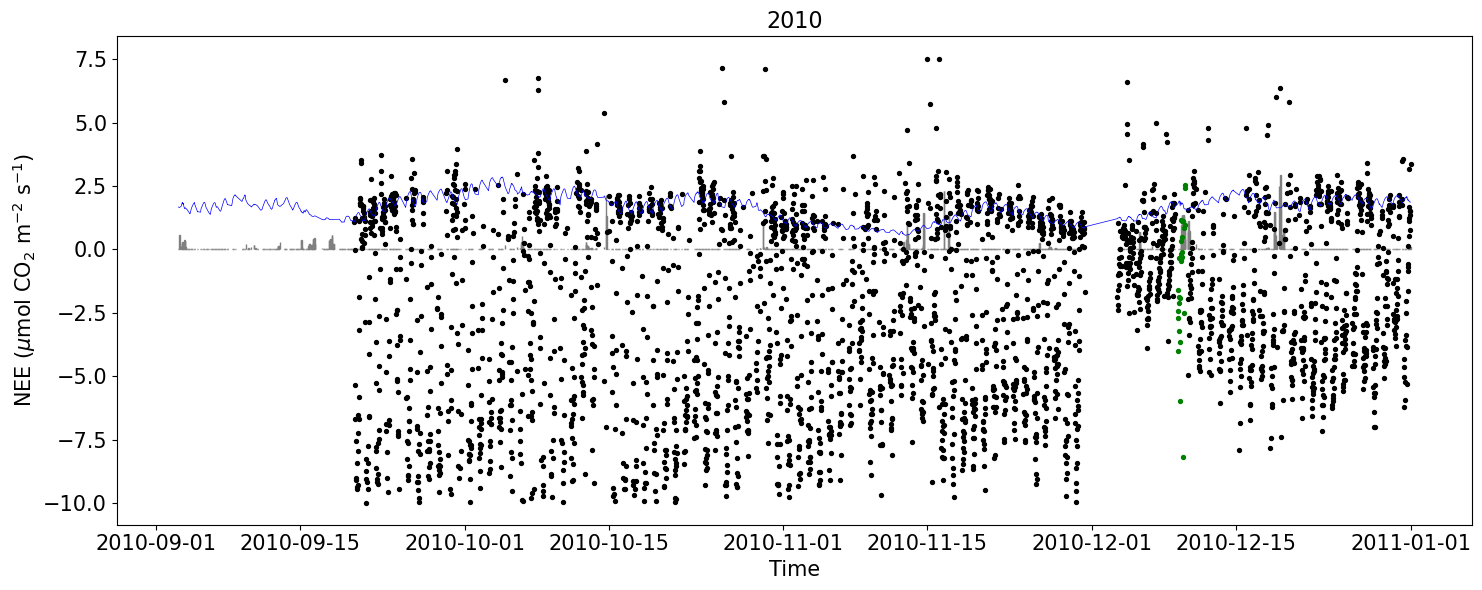

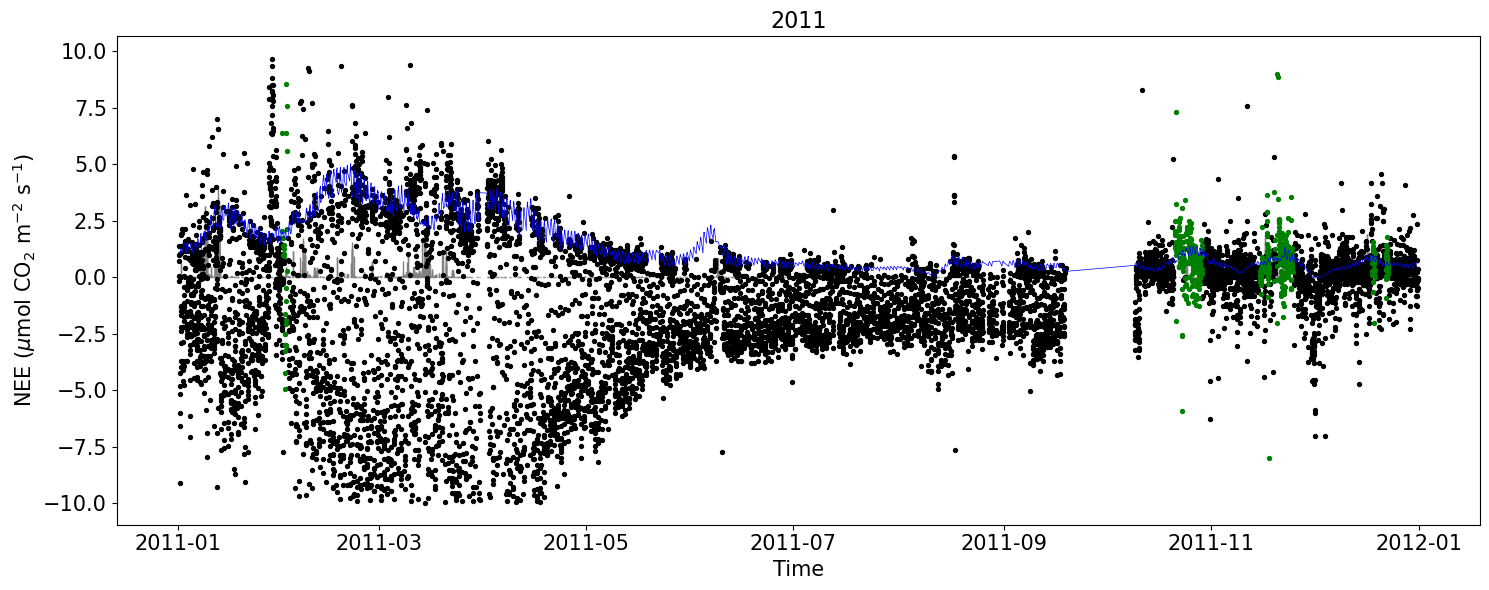

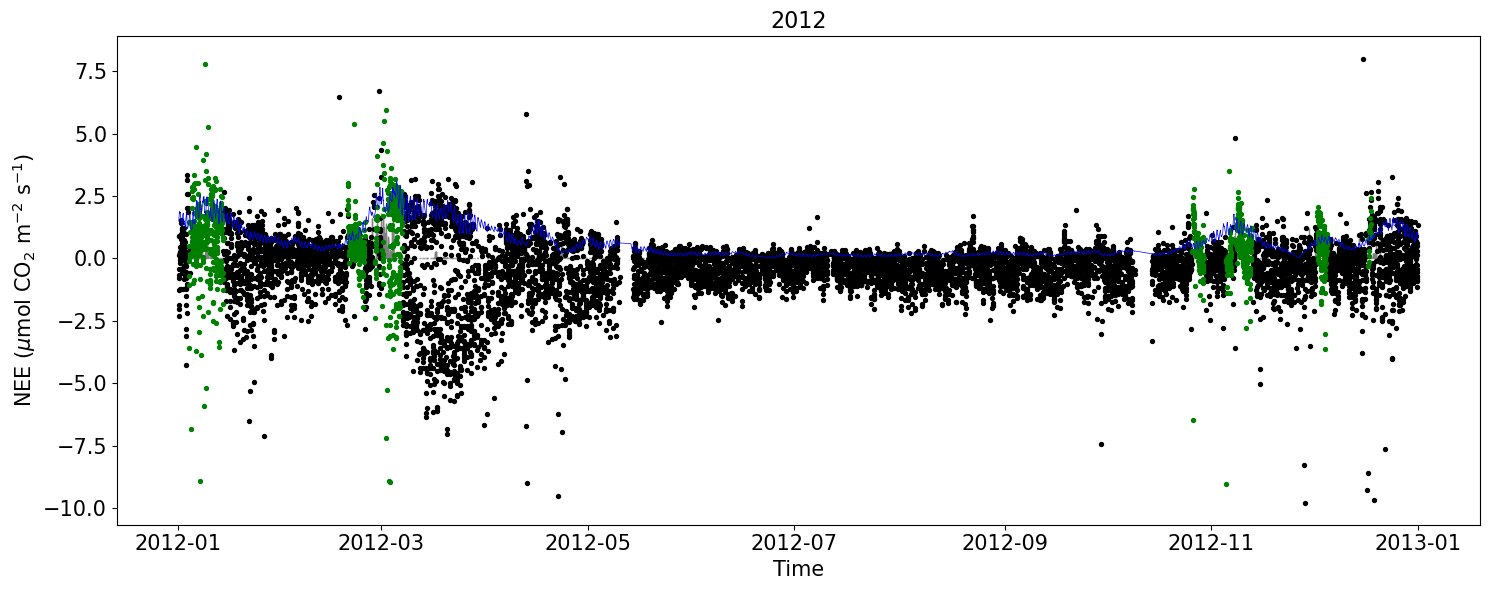

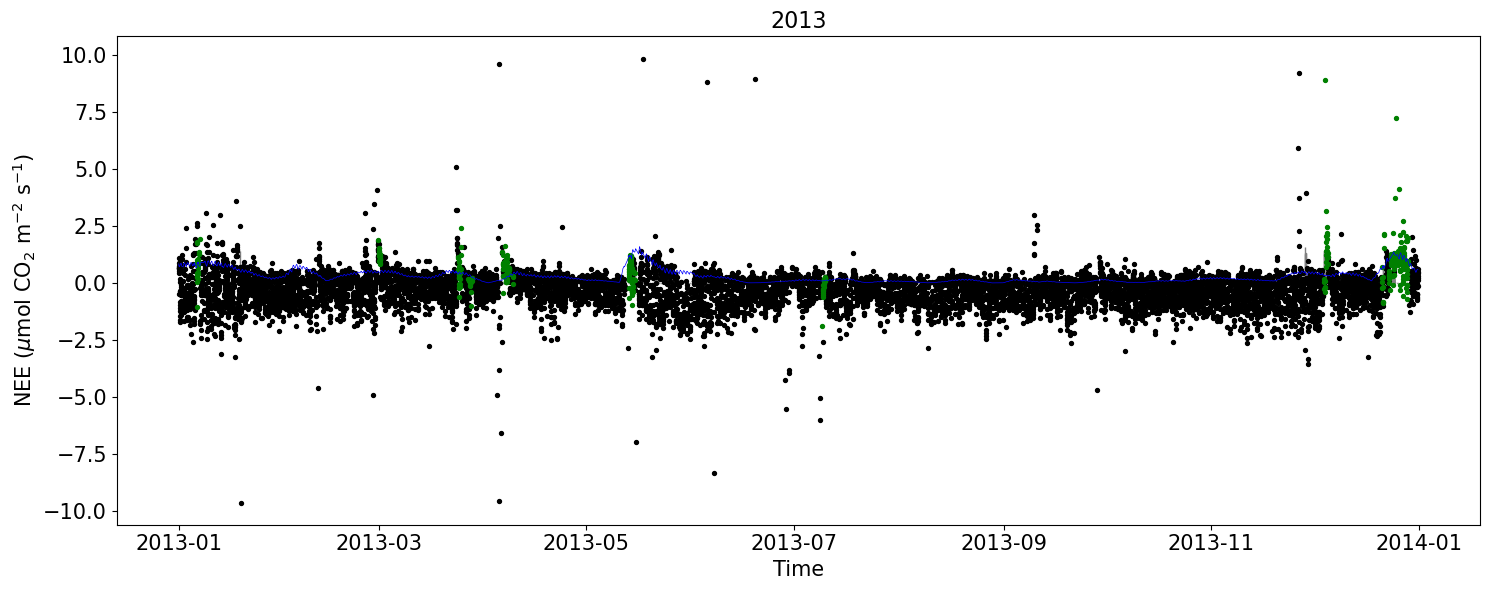

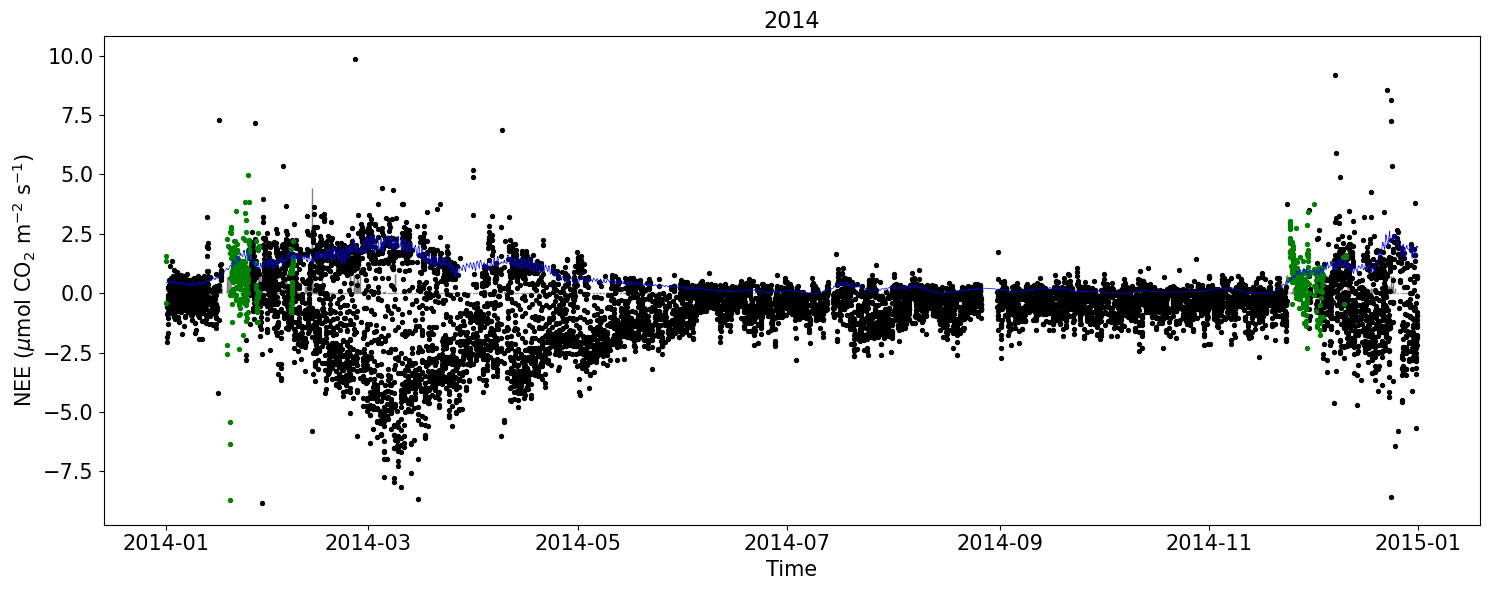

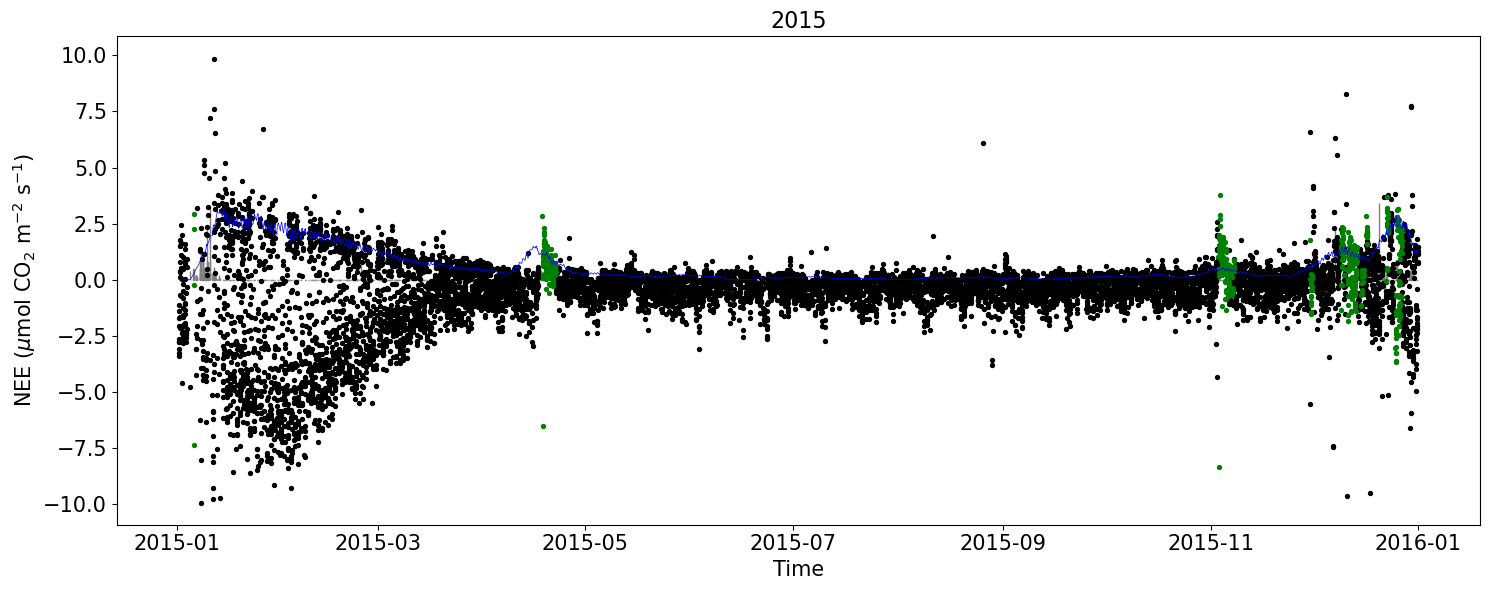

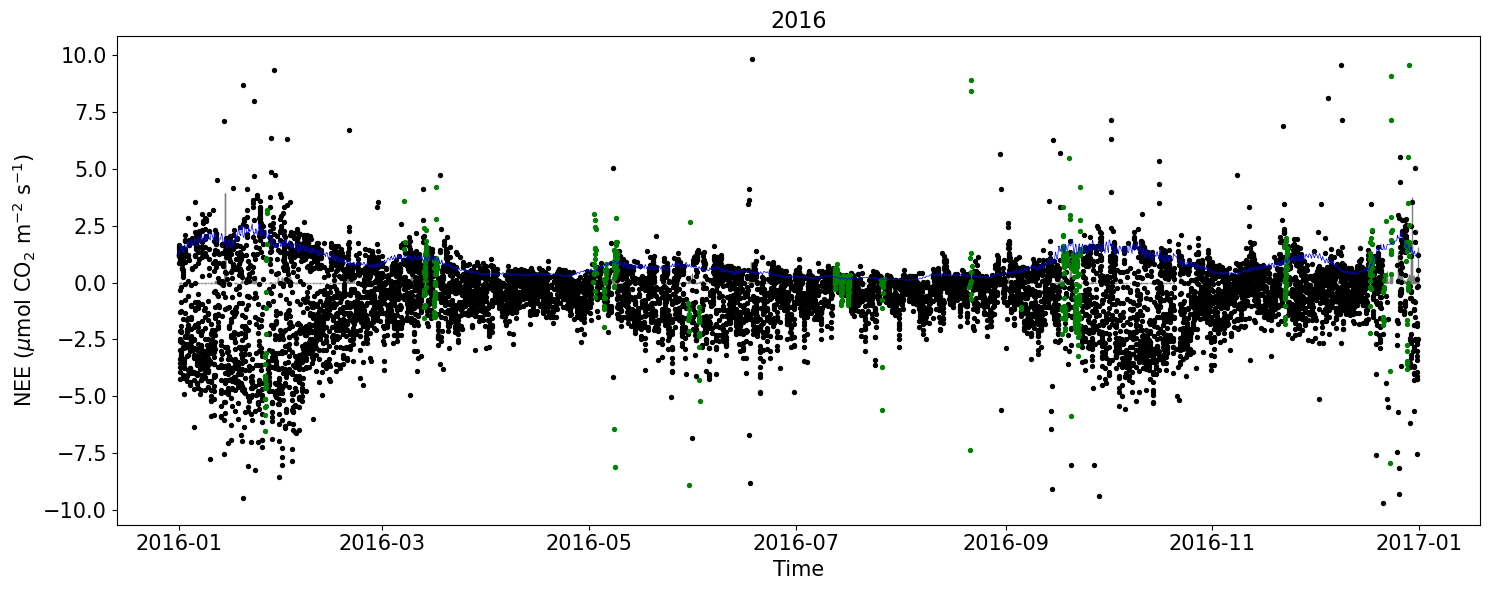

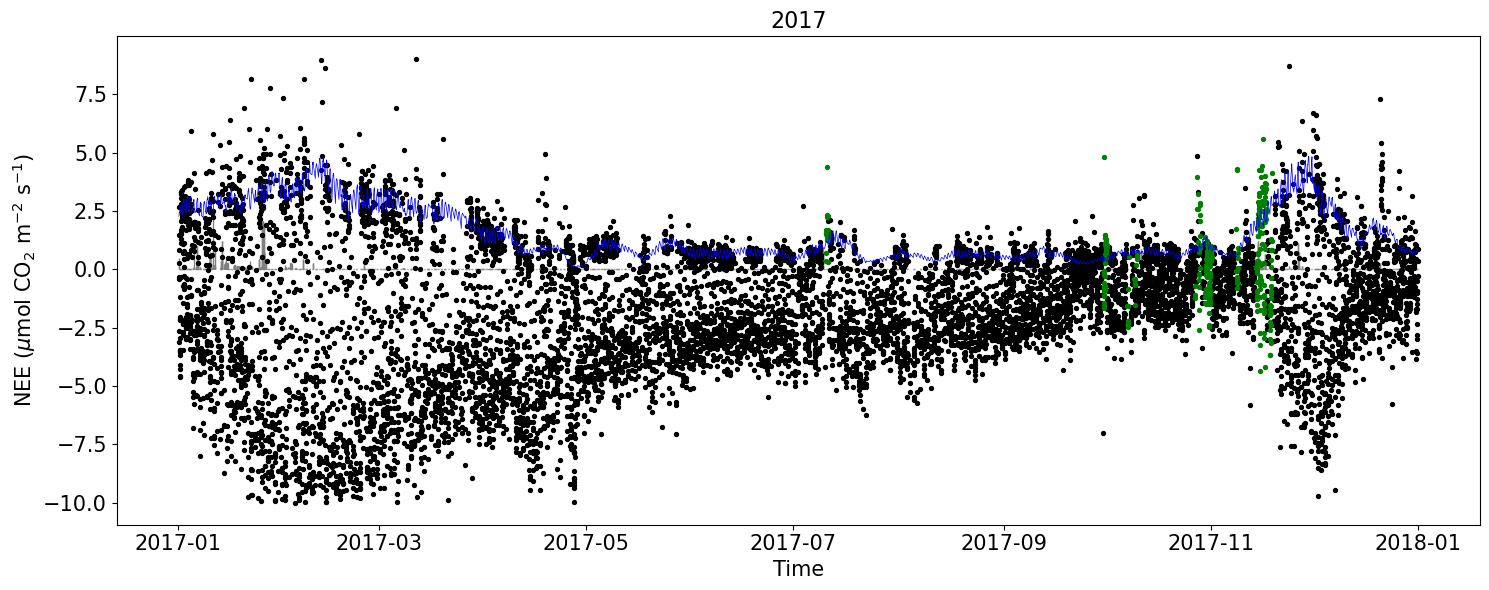

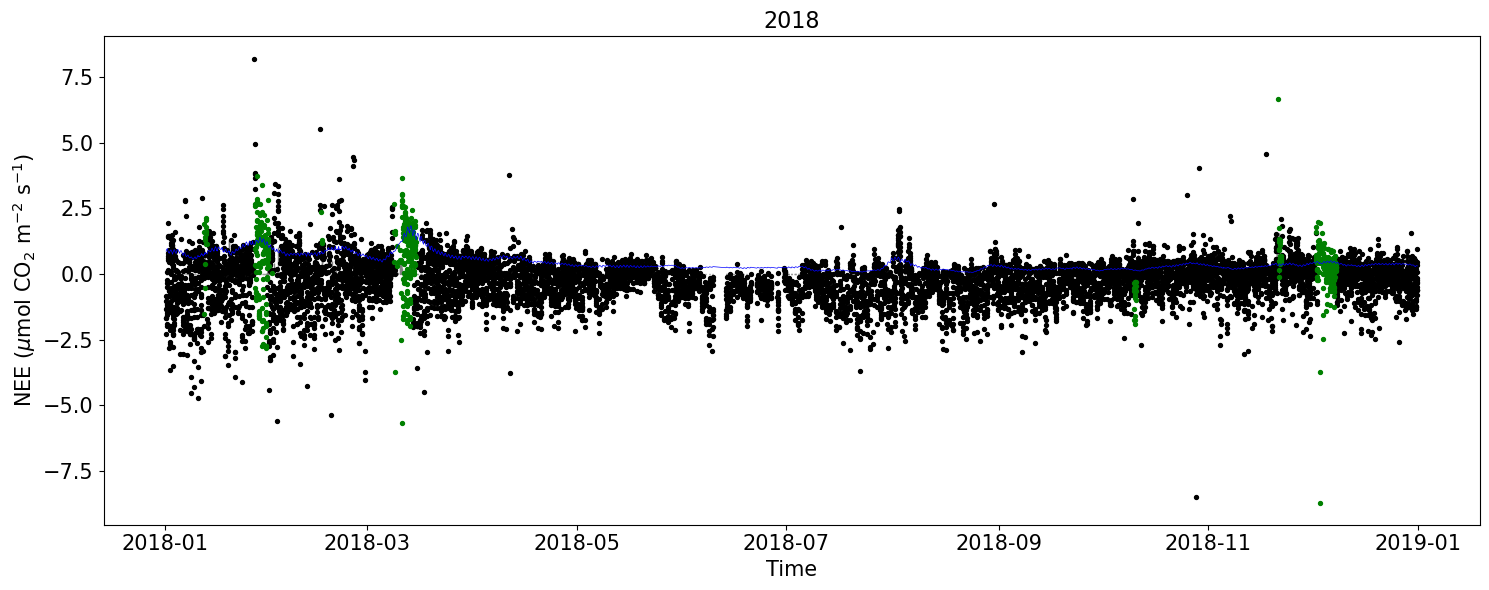

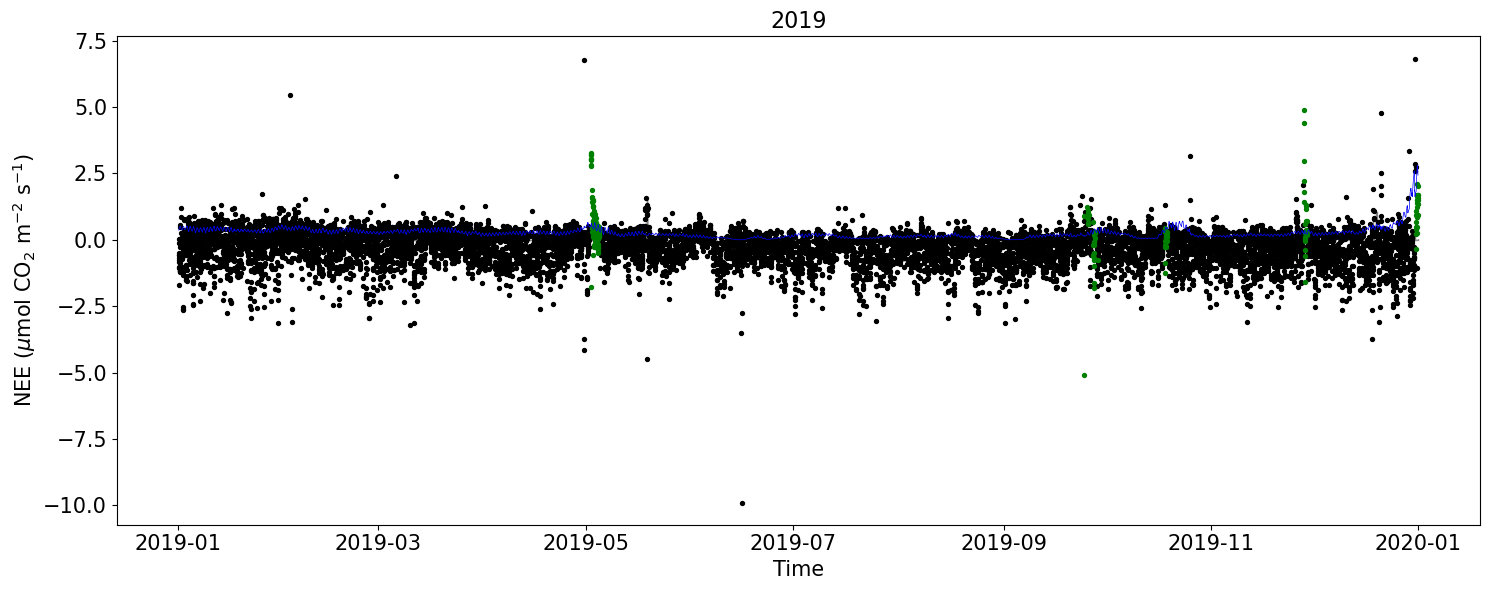

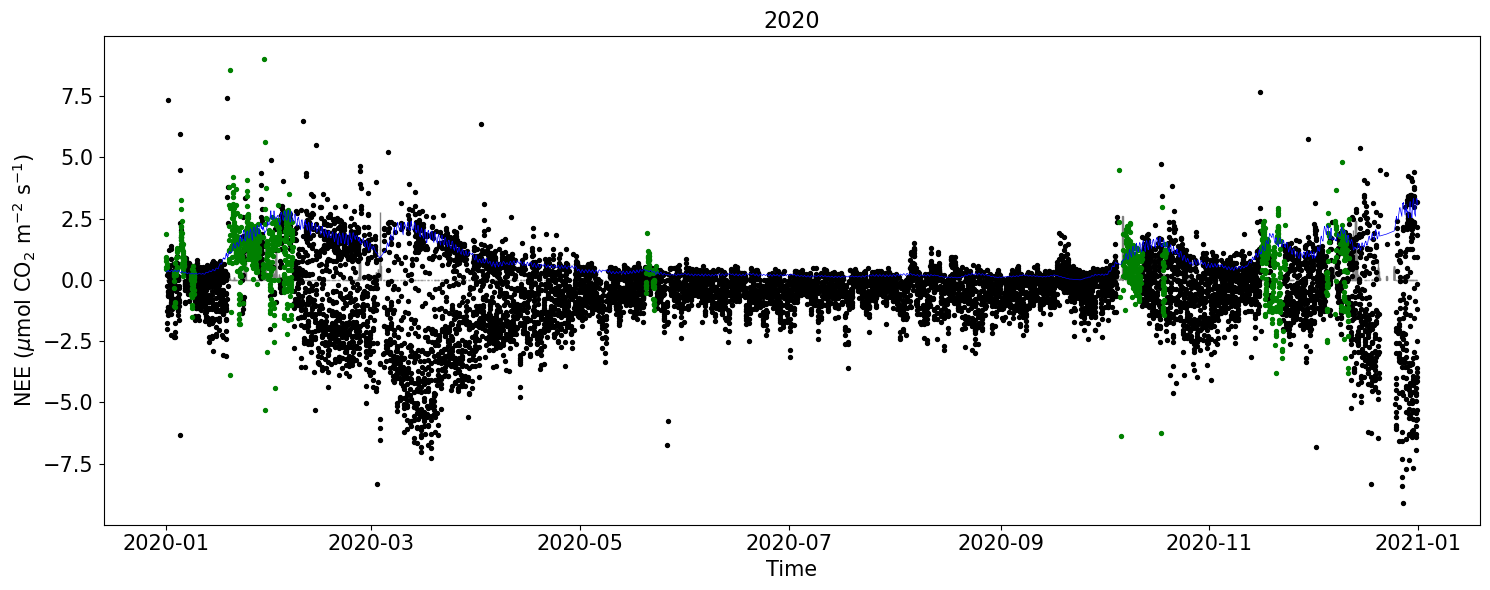

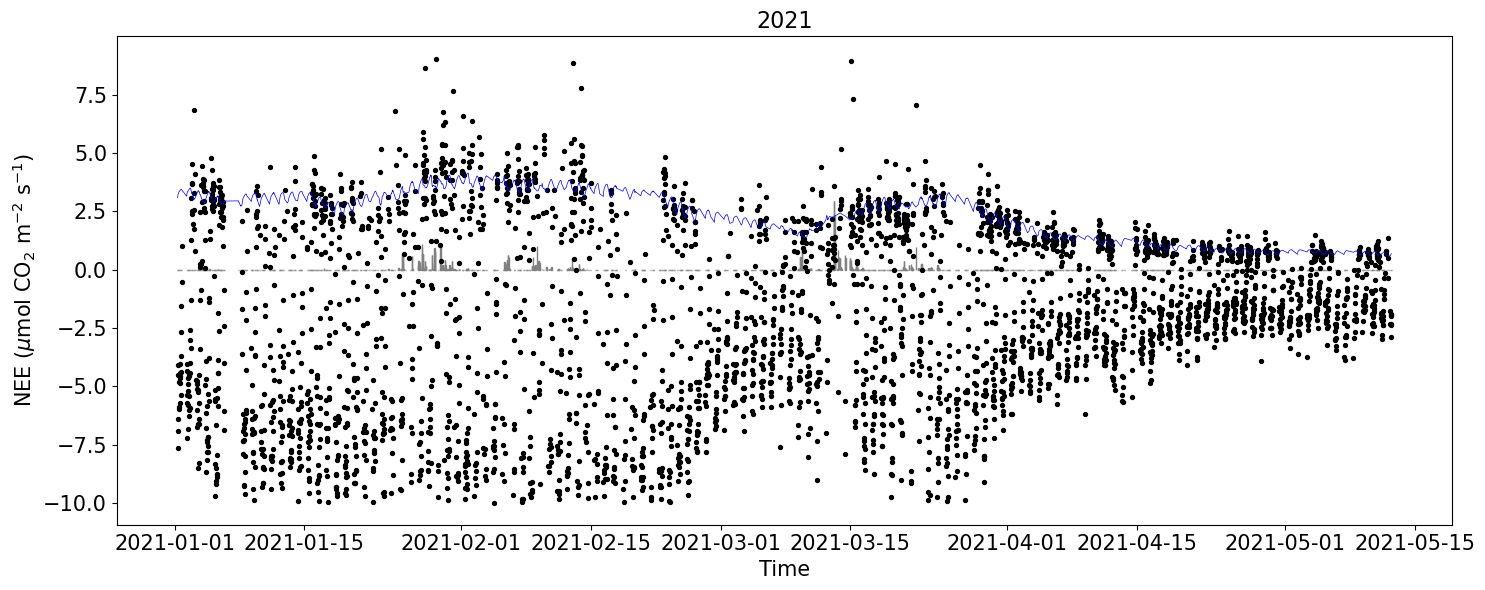

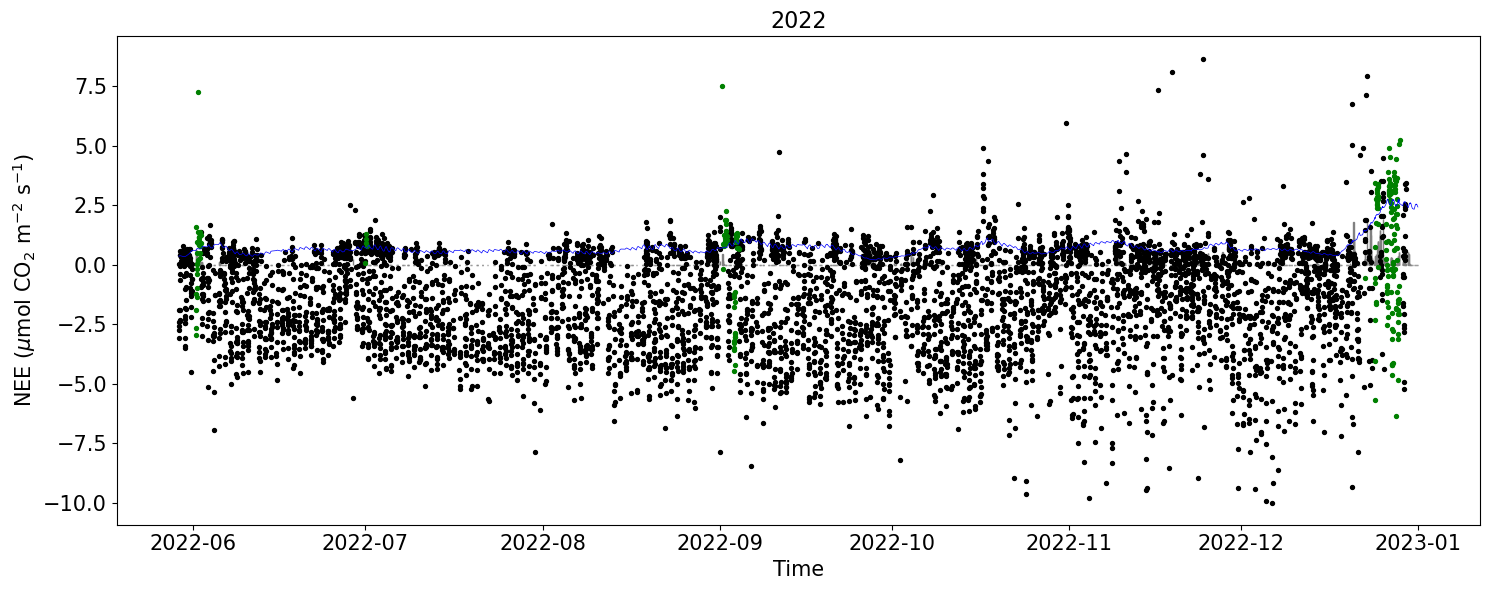

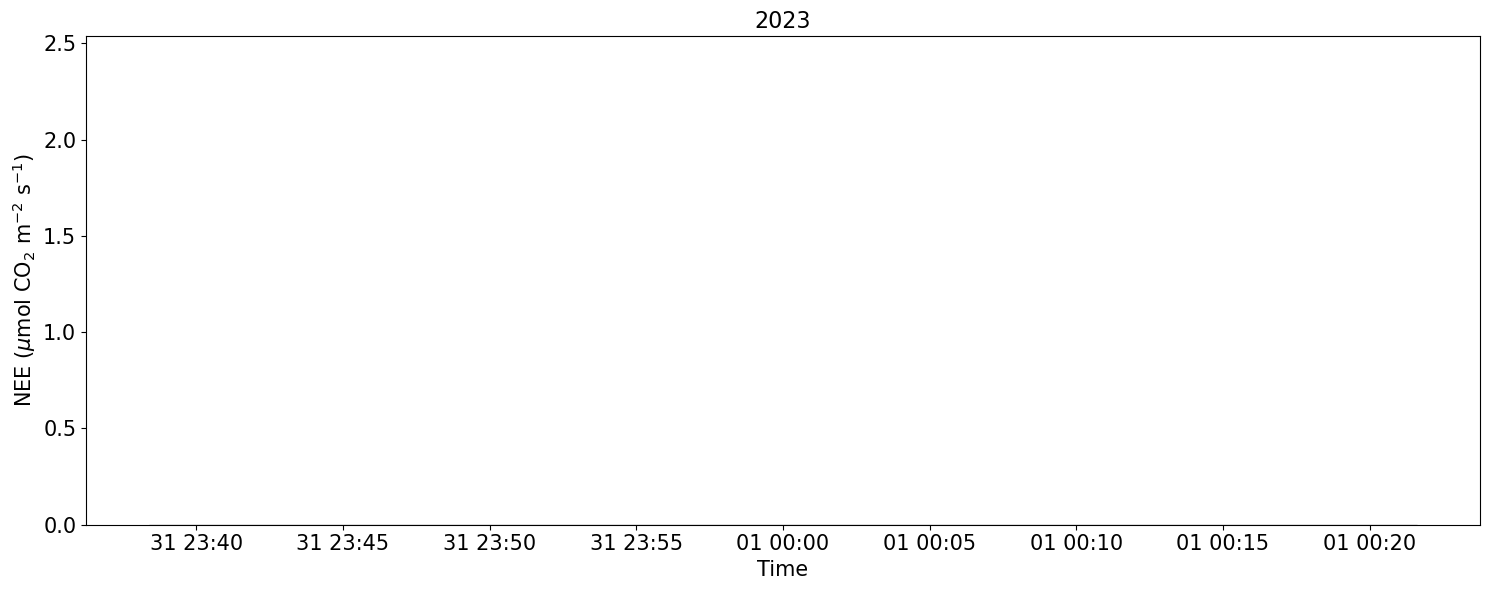

In [22]:
#Visualize

# Make sure Time_full is datetime
df_pulse["Time_full"] = pd.to_datetime(df_pulse["Time_full"])

# Loop through each year
for year in sorted(df_pulse["Year"].dropna().unique()):

    # Same filtering as your R subset()
    df_sub = df_pulse[
        (df_pulse["Year"] == year) &
        (df_pulse["NEE_VUT_REF_QC"] == 0) &
        (df_pulse["NEE_VUT_REF"] > -10) &
        (df_pulse["NEE_VUT_REF"] < 10)
    ].copy()

    # Sort by time
    df_sub = df_sub.sort_values("Time_full")

    fig, ax = plt.subplots(figsize=(15, 6))

    # Precipitation bars
    ax.bar(
        df_sub["Time_full"],
        df_sub["P_ERA"],
        width=0.03,
        color="gray",
        edgecolor="gray"
    )

    # RECO line
    ax.plot(
        df_sub["Time_full"],
        df_sub["RECO_NT_VUT_REF"],
        color="blue",
        linewidth=0.5
    )

    # NEE points colored by pulse_cluster
    colors = {
        0: "black",
        1: "#008000"
    }

    for pulse, color in colors.items():
        temp = df_sub[df_sub["pulse_cluster"] == pulse]

        ax.scatter(
            temp["Time_full"],
            temp["NEE_VUT_REF"],
            color=color,
            s=8,
            alpha=1,
            label="Pulse event" if pulse == 1 else None
        )

    ax.legend(fontsize=13)

    # Labels
    ax.set_xlabel("Time", fontsize=15)
    ax.set_ylabel(
        r"NEE ($\mu$mol CO$_2$ m$^{-2}$ s$^{-1}$)",
        fontsize=15
    )

    ax.set_title(str(int(year)), fontsize=16)

    # Theme similar to theme_bw()
    ax.tick_params(axis="both", labelsize=15)
    ax.grid(False)

    # Remove legend
    legend = ax.get_legend()
    if legend is not None:
        legend.remove()

    plt.tight_layout()
    plt.show()

In [20]:
##Save the labelled half-hourly datasets
df_pulse.to_csv("/Users/ngocnguyen/Library/CloudStorage/Box-Box/Projects/Birch_effect_paper/Results/Datasets/df_pulse_test.csv", index=False)

In [ ]:
#Extract SOP and EOP
df_pulse_update = (
    df_pulse[df_pulse['NEE_VUT_REF_QC'] == 0]
    .groupby('Time', group_keys=False)
    .apply(remove_bad_pulse)
    .reset_index(drop=True)
)

#Put all dates of pulses together in form of SOP and EOP
pulse_SOP_EOP = create_sop_eop_df(df_pulse_update)

# Create a list of pulse dates
pulse_dates = []
for index, row in pulse_SOP_EOP.iterrows():
    date_range = pd.date_range(start=row['SOP'], end=row['EOP'])
    pulse_dates.extend(date_range)
pulse_dates = [date.date() for date in pulse_dates]

# Modify RF based on the filtered pulse dates (filtered for bad pulses -  duration < 2 days)
df_pulse.loc[df_pulse['Time'].isin(pulse_dates), 'pulse_cluster'] = 1
df_pulse.loc[~df_pulse['Time'].isin(pulse_dates), 'pulse_cluster'] = 0

#################
#Calculate composite decay rate
all_pulse_day = []
day_index = []

for index, row in pulse_SOP_EOP.iterrows():
    num_days = (row['EOP'] - row['SOP']).days + 1  # +1 to include both start and end date
    days_range = pd.date_range(start=row['SOP'], periods=num_days)
    all_pulse_day.extend(days_range)
    day_index.extend(range(1, num_days + 1))

# Create a DataFrame
all_pulse_day_df = pd.DataFrame({
    'Time': all_pulse_day,
    'Day_index': day_index
})

#Write the df with start and end date of pulse events
save_dir_pulse = '/Users/ngocnguyen/Library/CloudStorage/Box-Box/Projects/Birch_effect_paper/Results/Datasets/Random_forest/non-training-sites/Manual-ML-pulse-SOP-EOP/' + site_name + '.csv'
pulse_SOP_EOP.to_csv(save_dir_pulse, index=False)

In [25]:
#Bias-correct
# Filtering the data
df_sub = df_pulse[(df_pulse['NEE_VUT_REF_QC'] == 0) & (df_pulse['Time'].isin(pulse_dates)) & (df_pulse['NEE_VUT_REF'].abs() < 30)]

# Computing mean values per day
mean_pulse = df_sub.groupby('Time')['NEE_VUT_REF'].mean().reset_index()

# Merging with all_pulse_day_df to get day indexes
NEE_day_index_df = pd.concat([all_pulse_day_df, mean_pulse], axis=1, join='outer')

# Finding maximum NEE_VUT_REF per day index
max_df = NEE_day_index_df.groupby('Day_index')['NEE_VUT_REF'].max().reset_index()

/var/folders/2m/ztjd6v_n5vjgq2lg484dz7740000gs/T/ipykernel_18929/1112199789.py:3: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  df_sub = df_pulse[(df_pulse['NEE_VUT_REF_QC'] == 0) & (df_pulse['Time'].isin(pulse_dates)) & (df_pulse['NEE_VUT_REF'].abs() < 30)]


In [31]:
# Fitting the curve
try:
    params, params_covariance = curve_fit(model, max_df['Day_index'], max_df['NEE_VUT_REF'], p0=[max(max_df['NEE_VUT_REF']), 0.1])
    decay_factor_composite = params[1]

    dir_pdf = '/Users/ngocnguyen/Library/CloudStorage/Box-Box/Projects/Birch_effect_paper/Results/Figures/RF-all-sites/'

    pdf_name =  dir_pdf + 'corrected_Reco/' + site_name + '.pdf'
    pdf_name_decay = dir_pdf + 'decay_curve/'+ site_name + '_decay_curve' + '.pdf'

    with PdfPages(pdf_name_decay) as pdf:
        # Plotting the data and the fit
        plt.scatter(max_df['Day_index'], max_df['NEE_VUT_REF'], c='blue', marker='o', label='Data')
        plt.plot(max_df['Day_index'], model(max_df['Day_index'], *params), color='red', label='Fitted function')
        plt.xlabel('Day Index')
        plt.ylabel('NEE_VUT_REF')
        plt.legend()
        pdf.savefig()  # saves the current figure into a pdf page
        plt.close()  # close the figure to free memory

    ##########
    #Bias-corrected for Reco and GPP

    # Process data
    all_pulse_df = pd.DataFrame()
    RECO_df_pulse_list = []


    for i in pulse_SOP_EOP.index:
        sop = pulse_SOP_EOP.loc[i, 'SOP']
        eop = pulse_SOP_EOP.loc[i, 'EOP']
        date_range = pd.date_range(sop, eop)
        date_range = [date.date() for date in date_range]

        # Filter RECO_df based on SOP to EOP range and conditions
        RECO_df_sub = df_pulse[(df_pulse['Time'].isin(date_range)) & (df_pulse['RECO_NT_VUT_REF'] > -9999) & (df_pulse['NEE_VUT_REF_QC'] == 0)]  

        if len(RECO_df_sub['Time'].unique()) > 2:
            # Group by Time and apply quantile function
            df_decay = RECO_df_sub.groupby('Time').agg({'NEE_VUT_REF': quantile_df, 'RECO_NT_VUT_REF': quantile_df}).reset_index()
            df_decay['Day_index'] = np.arange(len(df_decay))
            df_decay['correction_factor'] = 0

            # Try to fit model
            try:
                # Fit the exponential decay model
                def model(x, a, b):
                    return a * np.exp(-b * x)

                params, params_covariance = curve_fit(model, df_decay['Day_index'], df_decay['NEE_VUT_REF'], p0=[df_decay['NEE_VUT_REF'].max(), 0.1])
                ini_condition, decay_factor = params
                # Simulate p-values calculation (this is more complex in real scenarios)
                # Calculate t-values and p-values for the parameters
                standard_errors = np.sqrt(np.diag(params_covariance))
                t_values = params / standard_errors
                degrees_of_freedom = len(max_df) - len(params)
                ini_condition_p, decay_factor_p = params = [2 * (1 - t.cdf(np.abs(t_val), degrees_of_freedom)) for t_val in t_values]


                # Calculate correction factors based on the model
                for k in range(len(df_decay)):
                    decay_factor_effective = decay_factor if ini_condition_p < 0.1 and decay_factor_p < 0.1 else decay_factor_composite
                    correction_factor_0 = max(df_decay.loc[0:1, 'NEE_VUT_REF']) / max(df_decay.loc[0:1, 'RECO_NT_VUT_REF']) * np.exp(decay_factor_effective)
                    df_decay.at[k, 'correction_factor'] = correction_factor_0 * np.exp(-decay_factor_effective * k)

            except Exception as e:
                for k in range(len(df_decay)):
                    df_decay.at[k, 'correction_factor'] = max(df_decay.loc[0:1, 'NEE_VUT_REF']) / max(df_decay.loc[0:1, 'RECO_NT_VUT_REF']) * np.exp(decay_factor_composite)

            # Merge corrections back to subset data
            RECO_df_sub_new = pd.merge(RECO_df_sub, df_decay[['Time', 'correction_factor']], on='Time', how='left')
            RECO_df_sub_new['RECO_pulse'] = RECO_df_sub_new['RECO_NT_VUT_REF'] * RECO_df_sub_new['correction_factor']
            RECO_df_pulse_list.append(RECO_df_sub_new)

    # Combine all pulses into one DataFrame
    all_pulse_df = pd.concat(RECO_df_pulse_list)

    # Filter and update main DataFrame
    all_pulse_df_sub = all_pulse_df[all_pulse_df['correction_factor'] < 100]
    update_df = pd.merge(all_pulse_df_sub[['Time_full', 'correction_factor', 'RECO_pulse']], df_pulse, on='Time_full', how='outer')
    update_df['RECO_pulse'].fillna(update_df['RECO_NT_VUT_REF'], inplace=True)

    ##########
    #save the file
    save_file_dir = '/Users/ngocnguyen/Library/CloudStorage/Box-Box/Projects/Birch_effect_paper/Results/Datasets/Random_forest/non-training-sites/site-ALL-pulse-corrected-csv/'
    save_dir = save_file_dir + site_name + ".csv"
    update_df.to_csv(save_dir, index=False)

    ##########
    #Created graphs 
    with PdfPages(pdf_name) as pdf:
        for year in update_df["Year"].unique():

            df_pulse_yr = update_df[(update_df["Year"] == year) & 
                                          (update_df['NEE_VUT_REF_QC'] == 0)]

            fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10)) 

            ax1.scatter(df_pulse_yr['Time_full'], df_pulse_yr['NEE_VUT_REF'], label='yellow: pulse events', s = 5, 
                        c = df_pulse_yr['pulse_cluster'], cmap='viridis', alpha = 0.3)
            ax1.scatter(df_pulse_yr['Time_full'], df_pulse_yr['RECO_pulse'], s = 5, 
                        c = "red", alpha = 0.3, label ='corrected Reco')
            ax1.set_title('Random forest prediction - random split')
            ax1.set_xlabel('Time')
            ax1.set_ylabel('CO2 flux')
            ax1.legend()

            ax2.scatter(df_pulse_yr['Time_full'], df_pulse_yr['Daily_EF'], label='yellow: pulse events', s = 5, 
                        c = df_pulse_yr['pulse_cluster'], cmap='viridis', alpha = 0.3)
            ax2.scatter(df_pulse_yr['Time_full'], df_pulse_yr['P_ERA']/5, s = 5, 
                        c = "red", alpha = 0.3)
            ax2.set_title('EF and Precipitation')
            ax2.set_xlabel('Time')
            ax2.set_ylabel('Value')
            ax2.legend()

            pdf.savefig()  # saves the current figure into a pdf page
            plt.close()  # close the figure to free memory

except Exception as e:
    print(site_name + " do not have any pulse events or bias-correction fails")
except Exception as e:
    print(site_name + " cannot be read")

SyntaxError: unexpected EOF while parsing (814638566.py, line 118)

In [32]:
import os
import traceback
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.backends.backend_pdf import PdfPages
from scipy.optimize import curve_fit
from scipy.stats import t


# --------------------------------------------------
# Exponential decay model
# --------------------------------------------------
def model(x, a, b):
    return a * np.exp(-b * x)


try:

    # --------------------------------------------------
    # Make sure datetime columns are consistent
    # --------------------------------------------------
    df_pulse = df_pulse.copy()

    df_pulse["Time"] = pd.to_datetime(df_pulse["Time"])
    df_pulse["Time_full"] = pd.to_datetime(df_pulse["Time_full"])

    pulse_SOP_EOP = pulse_SOP_EOP.copy()
    pulse_SOP_EOP["SOP"] = pd.to_datetime(pulse_SOP_EOP["SOP"])
    pulse_SOP_EOP["EOP"] = pd.to_datetime(pulse_SOP_EOP["EOP"])


    # ==================================================
    # 1. FIT COMPOSITE DECAY CURVE
    # ==================================================

    max_df_fit = (
        max_df[
            ["Day_index", "NEE_VUT_REF"]
        ]
        .dropna()
        .copy()
    )

    params, params_covariance = curve_fit(
        model,
        max_df_fit["Day_index"],
        max_df_fit["NEE_VUT_REF"],
        p0=[
            max_df_fit["NEE_VUT_REF"].max(),
            0.1
        ],
        maxfev=10000
    )

    ini_condition_composite = params[0]
    decay_factor_composite = params[1]

    print(
        f"{site_name}: composite decay factor = "
        f"{decay_factor_composite:.4f}"
    )


    # ==================================================
    # 2. OUTPUT PATHS
    # ==================================================

    dir_pdf = (
        "/Users/ngocnguyen/Library/CloudStorage/Box-Box/"
        "Projects/Birch_effect_paper/Results/Figures/"
        "RF-all-sites/"
    )

    corrected_reco_dir = os.path.join(
        dir_pdf,
        "corrected_Reco"
    )

    decay_curve_dir = os.path.join(
        dir_pdf,
        "decay_curve"
    )

    os.makedirs(
        corrected_reco_dir,
        exist_ok=True
    )

    os.makedirs(
        decay_curve_dir,
        exist_ok=True
    )

    pdf_name = os.path.join(
        corrected_reco_dir,
        site_name + ".pdf"
    )

    pdf_name_decay = os.path.join(
        decay_curve_dir,
        site_name + "_decay_curve.pdf"
    )


    # ==================================================
    # 3. PLOT COMPOSITE DECAY CURVE
    # ==================================================

    with PdfPages(pdf_name_decay) as pdf:

        fig, ax = plt.subplots(
            figsize=(8, 6)
        )

        ax.scatter(
            max_df_fit["Day_index"],
            max_df_fit["NEE_VUT_REF"],
            c="blue",
            marker="o",
            label="Data"
        )

        ax.plot(
            max_df_fit["Day_index"],
            model(
                max_df_fit["Day_index"],
                *params
            ),
            color="red",
            label="Fitted function"
        )

        ax.set_xlabel("Day Index")
        ax.set_ylabel("NEE_VUT_REF")
        ax.legend()

        fig.tight_layout()

        pdf.savefig(fig)

        plt.close(fig)


    # ==================================================
    # 4. BIAS CORRECTION FOR EACH PULSE
    # ==================================================

    RECO_df_pulse_list = []

    for i in pulse_SOP_EOP.index:

        sop = pulse_SOP_EOP.loc[i, "SOP"]
        eop = pulse_SOP_EOP.loc[i, "EOP"]

        # ----------------------------------------------
        # Select data during pulse event
        # ----------------------------------------------

        RECO_df_sub = df_pulse[
            (df_pulse["Time"] >= sop) &
            (df_pulse["Time"] <= eop) &
            (df_pulse["RECO_NT_VUT_REF"] > -9999) &
            (df_pulse["NEE_VUT_REF_QC"] == 0)
        ].copy()


        # Need at least 3 unique days
        if RECO_df_sub["Time"].nunique() <= 2:
            continue


        # ----------------------------------------------
        # Calculate daily 98th percentile
        # ----------------------------------------------

        df_decay = (
            RECO_df_sub
            .groupby("Time")
            .agg(
                {
                    "NEE_VUT_REF": quantile_df,
                    "RECO_NT_VUT_REF": quantile_df
                }
            )
            .reset_index()
        )

        df_decay = (
            df_decay
            .dropna(
                subset=[
                    "NEE_VUT_REF",
                    "RECO_NT_VUT_REF"
                ]
            )
            .reset_index(drop=True)
        )


        if len(df_decay) <= 2:
            continue


        # Day 0, 1, 2, ...
        df_decay["Day_index"] = np.arange(
            len(df_decay)
        )


        # ==================================================
        # 5. FIT DECAY CURVE FOR INDIVIDUAL PULSE
        # ==================================================

        try:

            params_local, covariance_local = curve_fit(
                model,
                df_decay["Day_index"],
                df_decay["NEE_VUT_REF"],
                p0=[
                    df_decay["NEE_VUT_REF"].max(),
                    0.1
                ],
                maxfev=10000
            )

            ini_condition = params_local[0]
            decay_factor = params_local[1]


            # ----------------------------------------------
            # Calculate parameter standard errors
            # ----------------------------------------------

            standard_errors = np.sqrt(
                np.diag(
                    covariance_local
                )
            )


            # Correct degrees of freedom:
            # based on THIS pulse
            degrees_of_freedom = (
                len(df_decay) -
                len(params_local)
            )


            if (
                degrees_of_freedom > 0
                and np.all(
                    np.isfinite(
                        standard_errors
                    )
                )
                and np.all(
                    standard_errors > 0
                )
            ):

                t_values = (
                    params_local /
                    standard_errors
                )

                p_values = [
                    2 * (
                        1 -
                        t.cdf(
                            np.abs(t_val),
                            degrees_of_freedom
                        )
                    )
                    for t_val in t_values
                ]

                ini_condition_p = (
                    p_values[0]
                )

                decay_factor_p = (
                    p_values[1]
                )

            else:

                ini_condition_p = 1
                decay_factor_p = 1


            # ----------------------------------------------
            # Decide whether to use individual
            # or composite decay rate
            # ----------------------------------------------

            if (
                ini_condition_p < 0.1
                and decay_factor_p < 0.1
            ):

                decay_factor_effective = (
                    decay_factor
                )

            else:

                decay_factor_effective = (
                    decay_factor_composite
                )


        except Exception as fit_error:

            print(
                f"{site_name}: pulse fit failed "
                f"for {sop.date()} to {eop.date()}: "
                f"{fit_error}"
            )

            # Use composite decay rate
            decay_factor_effective = (
                decay_factor_composite
            )


        # ==================================================
        # 6. INITIAL CORRECTION FACTOR
        # ==================================================
        #
        # At Day_index = 0:
        #
        # correction_factor = NEE / RECO
        #
        # No extra exp(decay_factor) term.
        # ==================================================

        initial_nee = (
            df_decay[
                "NEE_VUT_REF"
            ]
            .iloc[:2]
            .max()
        )

        initial_reco = (
            df_decay[
                "RECO_NT_VUT_REF"
            ]
            .iloc[:2]
            .max()
        )


        # Avoid invalid division
        if (
            pd.isna(initial_nee)
            or pd.isna(initial_reco)
            or initial_reco == 0
        ):
            continue


        correction_factor_0 = (
            initial_nee /
            initial_reco
        )


        # ==================================================
        # 7. APPLY EXPONENTIAL DECAY
        # ==================================================
        #
        # Day 0:
        # NEE / RECO
        #
        # Day 1:
        # NEE / RECO * exp(-b)
        #
        # Day 2:
        # NEE / RECO * exp(-2b)
        # ==================================================

        df_decay[
            "correction_factor"
        ] = (

            correction_factor_0

            * np.exp(
                -decay_factor_effective
                * df_decay["Day_index"]
            )
        )


        # ==================================================
        # 8. MERGE DAILY CORRECTION TO HH DATA
        # ==================================================

        RECO_df_sub_new = pd.merge(
            RECO_df_sub,

            df_decay[
                [
                    "Time",
                    "correction_factor"
                ]
            ],

            on="Time",
            how="left"
        )


        # Correct Reco
        RECO_df_sub_new[
            "RECO_pulse"
        ] = (

            RECO_df_sub_new[
                "RECO_NT_VUT_REF"
            ]

            * RECO_df_sub_new[
                "correction_factor"
            ]
        )


        RECO_df_pulse_list.append(
            RECO_df_sub_new
        )


    # ==================================================
    # 9. COMBINE ALL PULSE EVENTS
    # ==================================================

    if len(RECO_df_pulse_list) == 0:

        raise ValueError(
            "No valid pulse events remained "
            "after filtering."
        )


    all_pulse_df = pd.concat(
        RECO_df_pulse_list,
        ignore_index=True
    )


    # ==================================================
    # 10. REMOVE EXTREME CORRECTION FACTORS
    # ==================================================

    all_pulse_df_sub = (
        all_pulse_df[
            all_pulse_df[
                "correction_factor"
            ] < 100
        ]
        .copy()
    )


    # Only keep correction information
    correction_df = (
        all_pulse_df_sub[
            [
                "Time_full",
                "correction_factor",
                "RECO_pulse"
            ]
        ]
        .drop_duplicates(
            "Time_full"
        )
    )


    # ==================================================
    # 11. MERGE BACK TO FULL DATAFRAME
    # ==================================================

    update_df = pd.merge(
        df_pulse,
        correction_df,
        on="Time_full",
        how="left"
    )


    # For non-pulse periods:
    # use original Reco
    update_df[
        "RECO_pulse"
    ] = (

        update_df[
            "RECO_pulse"
        ]

        .fillna(
            update_df[
                "RECO_NT_VUT_REF"
            ]
        )
    )


    # ==================================================
    # 12. SAVE CORRECTED DATA
    # ==================================================

    save_file_dir = (
        "/Users/ngocnguyen/Library/CloudStorage/Box-Box/"
        "Projects/Birch_effect_paper/Results/Datasets/"
        "Random_forest/non-training-sites/"
        "site-ALL-pulse-corrected-csv/"
    )


    os.makedirs(
        save_file_dir,
        exist_ok=True
    )


    save_dir = os.path.join(
        save_file_dir,
        site_name + ".csv"
    )


    update_df.to_csv(
        save_dir,
        index=False
    )


    # ==================================================
    # 13. CREATE YEARLY DIAGNOSTIC FIGURES
    # ==================================================

    with PdfPages(pdf_name) as pdf:

        for year in sorted(
            update_df[
                "Year"
            ]
            .dropna()
            .unique()
        ):

            df_pulse_yr = (
                update_df[
                    (update_df["Year"] == year) &
                    (
                        update_df[
                            "NEE_VUT_REF_QC"
                        ] == 0
                    )
                ]
                .copy()
            )


            if len(df_pulse_yr) == 0:
                continue


            fig, (ax1, ax2) = plt.subplots(
                2,
                1,
                figsize=(12, 10)
            )


            # ------------------------------------------
            # Separate pulse / non-pulse observations
            # ------------------------------------------

            normal = df_pulse_yr[
                df_pulse_yr[
                    "pulse_cluster"
                ] != 1
            ]


            pulse = df_pulse_yr[
                df_pulse_yr[
                    "pulse_cluster"
                ] == 1
            ]


            # ==========================================
            # Panel 1: NEE + corrected Reco
            # ==========================================

            ax1.scatter(
                normal["Time_full"],
                normal["NEE_VUT_REF"],
                s=5,
                c="black",
                alpha=0.3
            )


            ax1.scatter(
                pulse["Time_full"],
                pulse["NEE_VUT_REF"],
                s=5,
                c="green",
                alpha=0.6,
                label="Pulse event"
            )


            ax1.scatter(
                df_pulse_yr[
                    "Time_full"
                ],
                df_pulse_yr[
                    "RECO_pulse"
                ],
                s=5,
                c="red",
                alpha=0.3,
                label="Corrected Reco"
            )


            ax1.set_title(
                "Random forest prediction - random split"
            )

            ax1.set_xlabel(
                "Time"
            )

            ax1.set_ylabel(
                r"CO$_2$ flux"
            )

            ax1.legend()


            # ==========================================
            # Panel 2: EF + precipitation
            # ==========================================

            ax2.scatter(
                normal["Time_full"],
                normal["Daily_EF"],
                s=5,
                c="black",
                alpha=0.3
            )


            ax2.scatter(
                pulse["Time_full"],
                pulse["Daily_EF"],
                s=5,
                c="green",
                alpha=0.6,
                label="Pulse event"
            )


            ax2.scatter(
                df_pulse_yr[
                    "Time_full"
                ],
                df_pulse_yr[
                    "P_ERA"
                ] / 5,
                s=5,
                c="red",
                alpha=0.3,
                label="P_ERA / 5"
            )


            ax2.set_title(
                "EF and Precipitation"
            )

            ax2.set_xlabel(
                "Time"
            )

            ax2.set_ylabel(
                "Value"
            )

            ax2.legend()


            fig.tight_layout()

            pdf.savefig(fig)

            plt.close(fig)


    print(
        f"{site_name}: bias correction completed successfully"
    )


# ==================================================
# SHOW THE ACTUAL ERROR IF SOMETHING FAILS
# ==================================================

except Exception as e:

    print(
        f"{site_name} failed: {e}"
    )

    traceback.print_exc()

AU-ASM: composite decay factor = 0.3084
AU-ASM: bias correction completed successfully
